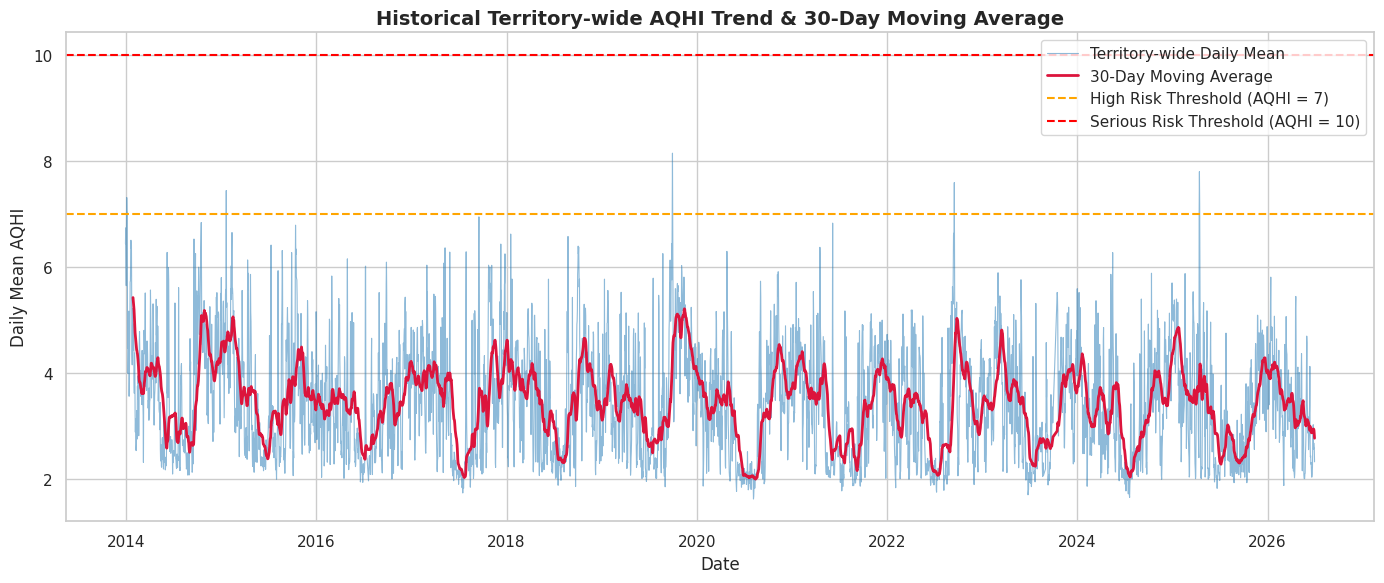

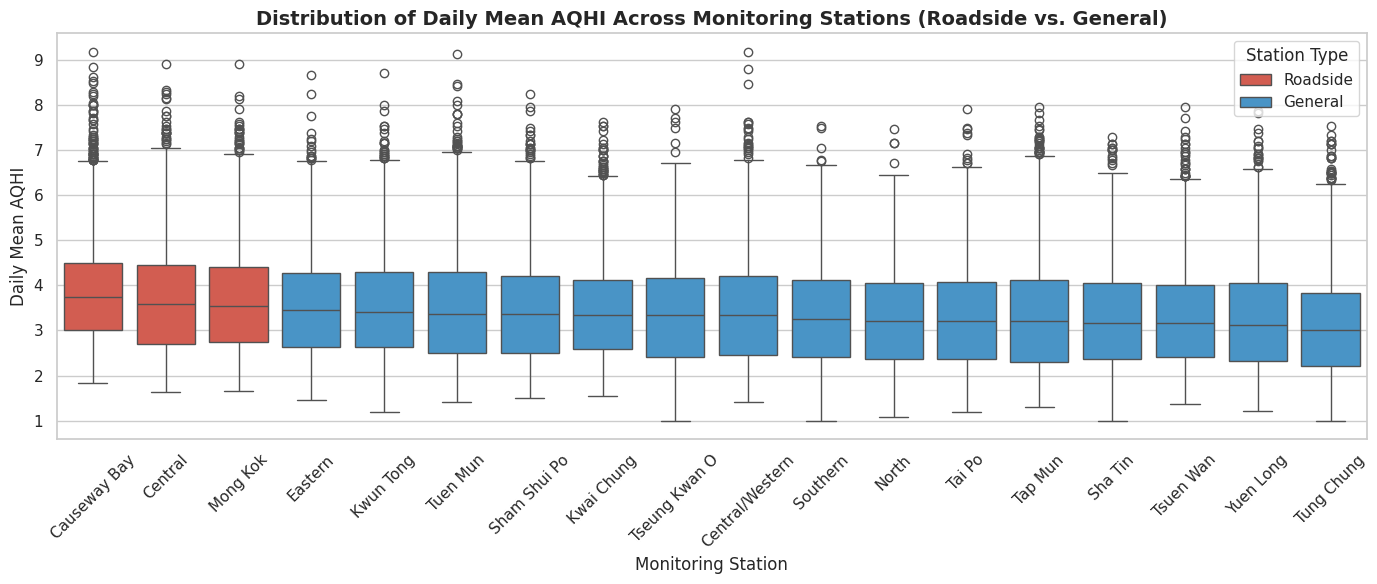

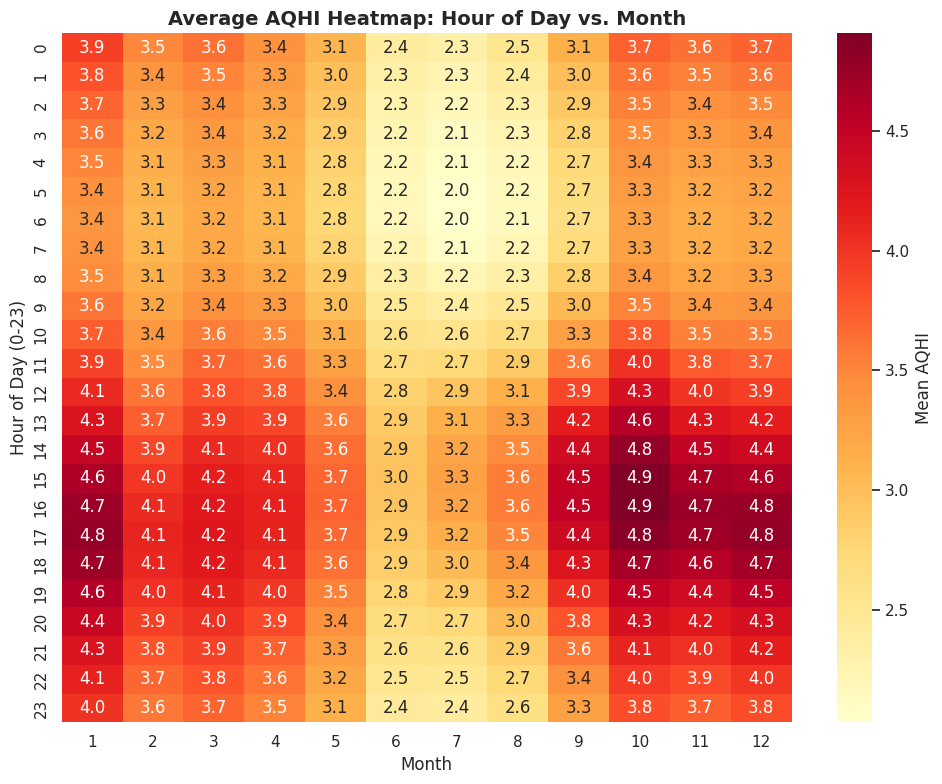

/var/folders/dn/8xt3xqsn3ysf586z6l0zvfym0000gn/T/ipykernel_3048/2744035335.py:113: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=station_10plus.index, y=station_10plus.values, palette='Reds_r')


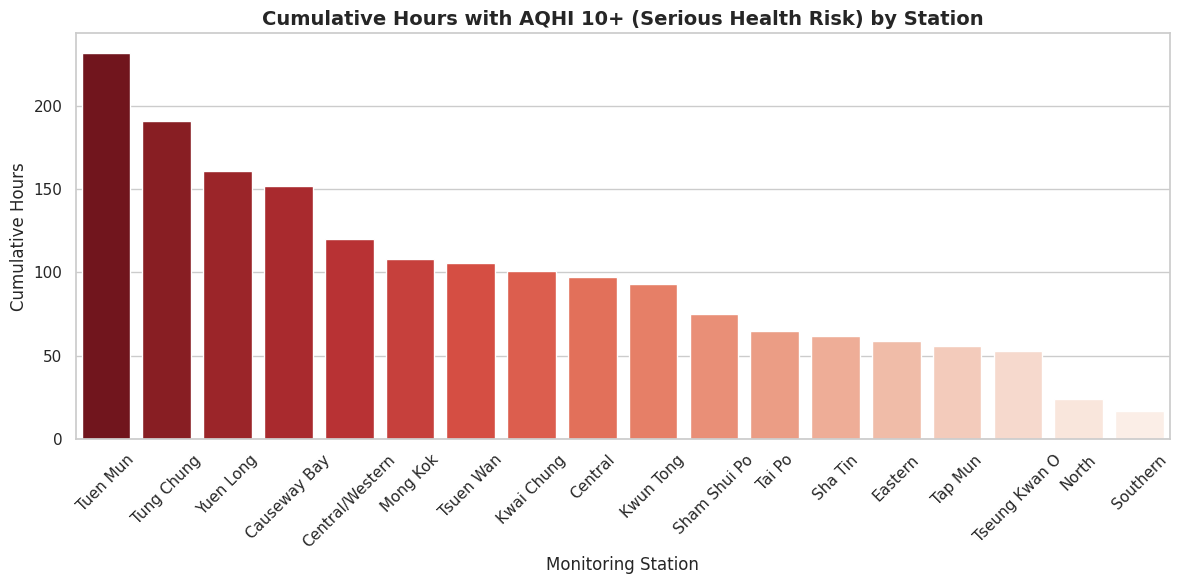

4 张图片已更新并成功保存至 Google Drive 路径：/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/Photos/1
執行時間: 6.7333 秒


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

import time

# 記錄開始時間
start_time = time.time()

# 執行的程式碼
#time.sleep(1)  # 範例：暫停 1 秒




# 1. 创建保存路径
#save_dir = '/content/drive/MyDrive/CS5488/Photos/1'
save_dir = '/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/Photos/1'
df_daily = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_daily.parquet')
df_long = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_long.parquet')

os.makedirs(save_dir, exist_ok=True)
''
# 2. 设置绘图风格
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# 3. 加载数据
df_daily = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_daily.parquet')
df_long = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_long.parquet')

df_daily['date'] = pd.to_datetime(df_daily['date'])
df_long['datetime'] = pd.to_datetime(df_long['datetime'])

# 定义 3 个路边监测站
roadside_stations = ['Causeway Bay', 'Central', 'Mong Kok']

# ==========================================
# 图 1：全港 AQHI 长期月度/年度时间序列演变趋势图
# ==========================================
df_daily_overall = df_daily.groupby('date')['aqhi_daily_mean'].mean().reset_index()

plt.figure(figsize=(14, 6))
plt.plot(df_daily_overall['date'], df_daily_overall['aqhi_daily_mean'], color='#1f77b4', linewidth=0.8, alpha=0.5, label='Territory-wide Daily Mean')

df_daily_overall['ma_30'] = df_daily_overall['aqhi_daily_mean'].rolling(window=30).mean()
plt.plot(df_daily_overall['date'], df_daily_overall['ma_30'], color='crimson', linewidth=2, label='30-Day Moving Average')

# 添加高风险 (AQHI=7) 与严重风险 (AQHI=10) 警戒线
plt.axhline(y=7, color='orange', linestyle='--', linewidth=1.5, label='High Risk Threshold (AQHI = 7)')
plt.axhline(y=10, color='red', linestyle='--', linewidth=1.5, label='Serious Risk Threshold (AQHI = 10)')

plt.title('Historical Territory-wide AQHI Trend & 30-Day Moving Average', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Daily Mean AQHI', fontsize=12)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(f'{save_dir}/chart1_trend_moving_avg.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 图 2：监测站点及类型（路边站 vs 一般站）AQHI 分布对比箱线图
# ==========================================
# 标注站点类型
df_daily['station_type'] = df_daily['station'].apply(lambda x: 'Roadside' if x in roadside_stations else 'General')
order = df_daily.groupby('station')['aqhi_daily_mean'].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df_daily,
    x='station',
    y='aqhi_daily_mean',
    order=order,
    hue='station_type',
    palette={'Roadside': '#e74c3c', 'General': '#3498db'},
    dodge=False
)

plt.title('Distribution of Daily Mean AQHI Across Monitoring Stations (Roadside vs. General)', fontsize=14, fontweight='bold')
plt.xlabel('Monitoring Station', fontsize=12)
plt.ylabel('Daily Mean AQHI', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Station Type', loc='upper right')
plt.tight_layout()
plt.savefig(f'{save_dir}/chart2_boxplot_station_type.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 图 3：24小时昼夜 vs 12个月份交叉平均 AQHI 热力图
# ==========================================
df_long['hour'] = df_long['datetime'].dt.hour
df_long['month'] = df_long['datetime'].dt.month

heatmap_data = df_long.pivot_table(index='hour', columns='month', values='aqhi', aggfunc='mean')

plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt=".1f", cbar_kws={'label': 'Mean AQHI'})
plt.title('Average AQHI Heatmap: Hour of Day vs. Month', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Hour of Day (0-23)', fontsize=12)
plt.tight_layout()
plt.savefig(f'{save_dir}/chart3_heatmap_hour_month.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 图 4：各监测站 AQHI≥10 严重风险累计小时数分布图
# ==========================================
plt.figure(figsize=(12, 6))
station_10plus = df_daily.groupby('station')['is_10plus_hours'].sum().sort_values(ascending=False)

sns.barplot(x=station_10plus.index, y=station_10plus.values, palette='Reds_r')
plt.title('Cumulative Hours with AQHI 10+ (Serious Health Risk) by Station', fontsize=14, fontweight='bold')
plt.xlabel('Monitoring Station', fontsize=12)
plt.ylabel('Cumulative Hours', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{save_dir}/chart4_10plus_hours.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"4 张图片已更新并成功保存至 Google Drive 路径：{save_dir}")

# 記錄結束時間
end_time = time.time()

print(f"執行時間: {end_time - start_time:.4f} 秒")

In [13]:
import pandas as pd
import numpy as np

import time

# 記錄開始時間
start_time = time.time()

# 執行的程式碼
#time.sleep(1)  # 範例：暫停 1 秒

# 1. 加载数据集
#df_daily = pd.read_parquet('/content/aqhi_clean_daily.parquet')
#df_long = pd.read_parquet('/content/aqhi_clean_long.parquet')


df_daily = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_daily.parquet')
df_long = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_long.parquet')


df_daily['date'] = pd.to_datetime(df_daily['date'])
df_long['datetime'] = pd.to_datetime(df_long['datetime'])
df_long['month'] = df_long['datetime'].dt.month
df_long['hour'] = df_long['datetime'].dt.hour

# 2. 区分路边站与一般站
roadside_stations = ['Causeway Bay', 'Central', 'Mong Kok']
df_long['station_type'] = df_long['station'].apply(lambda x: 'Roadside' if x in roadside_stations else 'General')
df_daily['station_type'] = df_daily['station'].apply(lambda x: 'Roadside' if x in roadside_stations else 'General')

# ==========================================
# 维度 1：全港 AQHI 宏观统计指标汇总表计算 (基于 hourly df_long)
# ==========================================
def calc_macro_stats(series):
    return pd.Series({
        '最小值 (Min)': series.min(),
        '25% 分位数': series.quantile(0.25),
        '中位数 (Median)': series.median(),
        '75% 分位数': series.quantile(0.75),
        '最大值 (Max)': series.max(),
        '全局均值 (Mean)': round(series.mean(), 2),
        '标准差 (Std)': round(series.std(), 2)
    })

# 定义季节子集 (冬季: 12, 1, 2月; 夏季: 6, 7, 8月)
roadside_aqhi = df_long[df_long['station_type'] == 'Roadside']['aqhi']
general_aqhi = df_long[df_long['station_type'] == 'General']['aqhi']
winter_aqhi = df_long[df_long['month'].isin([12, 1, 2])]['aqhi']
summer_aqhi = df_long[df_long['month'].isin([6, 7, 8])]['aqhi']

macro_summary = pd.DataFrame({
    '路边监测站 (Roadside)': calc_macro_stats(roadside_aqhi),
    '一般监测站 (General)': calc_macro_stats(general_aqhi),
    '冬季 (Winter)': calc_macro_stats(winter_aqhi),
    '夏季 (Summer)': calc_macro_stats(summer_aqhi)
}).T

print("==========================================")
print("1. 真实全港 AQHI 宏观统计指标汇总表 (小时级精确值)")
print("==========================================")
print(macro_summary.to_markdown())

# ==========================================
# 维度 2：空间站点分布 AQHI ≥ 10 累计小时数统计
# ==========================================
# 基于 hourly df_long 统计真实 AQHI>=10 的小时数
df_long['is_10plus'] = df_long['aqhi'] >= 10
hours_10plus = df_long.groupby(['station', 'station_type'])['is_10plus'].sum().reset_index()
hours_10plus.columns = ['Station', 'Type', 'Hours_AQHI_10plus']
hours_10plus = hours_10plus.sort_values(by='Hours_AQHI_10plus', ascending=False)

total_hours_10plus = hours_10plus['Hours_AQHI_10plus'].sum()
roadside_hours_10plus = hours_10plus[hours_10plus['Type'] == 'Roadside']['Hours_AQHI_10plus'].sum()
general_hours_10plus = hours_10plus[hours_10plus['Type'] == 'General']['Hours_AQHI_10plus'].sum()

print("\n==========================================")
print("2. 监测站 AQHI≥10 严重风险小时数精确统计")
print("==========================================")
print(hours_10plus.to_string(index=False))
print(f"\n全港所有站点累计 AQHI≥10 总小时数: {total_hours_10plus}")
print(f"3个路边站累计: {roadside_hours_10plus} 小时 (占比: {roadside_hours_10plus/total_hours_10plus*100:.2f}%)")
print(f"15个一般站累计: {general_hours_10plus} 小时 (占比: {general_hours_10plus/total_hours_10plus*100:.2f}%)")

# ==========================================
# 维度 3：昼夜 (0-23时) × 月份 (1-12月) 热力图交叉均值数据提取
# ==========================================
heatmap_matrix = df_long.pivot_table(index='hour', columns='month', values='aqhi', aggfunc='mean')

# 提取冬季 (12, 1, 2月) 午后至傍晚 (14:00–19:00) 单元格均值区间
winter_afternoon = heatmap_matrix.loc[14:19, [12, 1, 2]]
# 提取夏季 (6, 7, 8月) 全天 (0–23时) 单元格均值区间
summer_allday = heatmap_matrix.loc[:, [6, 7, 8]]

print("\n==========================================")
print("3. 热力图关键时段均值核验")
print("==========================================")
print(f"冬季午后至傍晚 (12-2月, 14-19时) 单元格均值范围: {winter_afternoon.min().min():.2f} ~ {winter_afternoon.max().max():.2f}")
print(f"夏季全天 (6-8月, 0-23时) 单元格均值范围: {summer_allday.min().min():.2f} ~ {summer_allday.max().max():.2f}")

# 記錄結束時間
end_time = time.time()

print(f"執行時間: {end_time - start_time:.4f} 秒")

1. 真实全港 AQHI 宏观统计指标汇总表 (小时级精确值)
|                       |   最小值 (Min) |   25% 分位数 |   中位数 (Median) |   75% 分位数 |   最大值 (Max) |   全局均值 (Mean) |   标准差 (Std) |
|:----------------------|---------------:|-------------:|------------------:|-------------:|---------------:|------------------:|---------------:|
| 路边监测站 (Roadside) |              1 |            3 |                 4 |            5 |             10 |              3.74 |           1.34 |
| 一般监测站 (General)  |              1 |            2 |                 3 |            4 |             10 |              3.37 |           1.33 |
| 冬季 (Winter)         |              1 |            3 |                 4 |            5 |             10 |              3.83 |           1.2  |
| 夏季 (Summer)         |              1 |            2 |                 2 |            3 |             10 |              2.65 |           1.13 |

2. 监测站 AQHI≥10 严重风险小时数精确统计
        Station     Type  Hours_AQHI_10plus
       Tuen Mun  General                465
     T

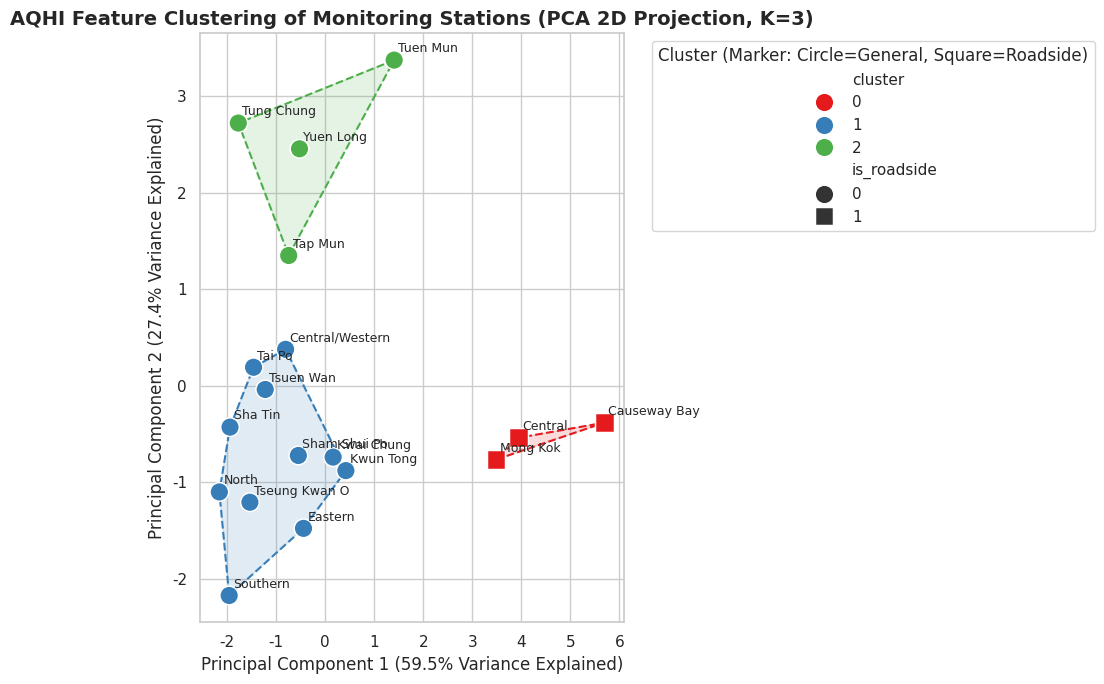

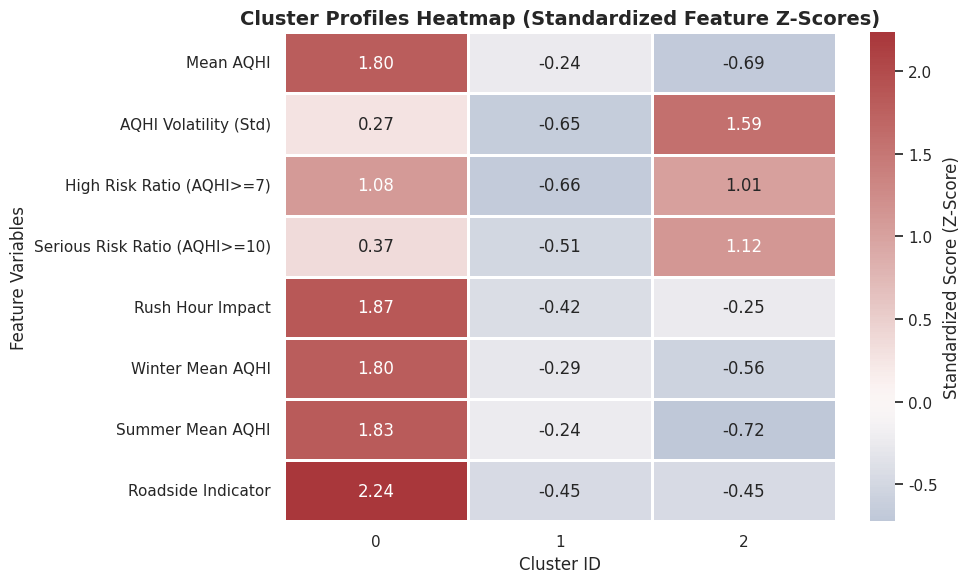

=== Station Grouping by Cluster ===

Cluster 0 (3 stations):
Station list: ['Causeway Bay', 'Central', 'Mong Kok']

Cluster 1 (11 stations):
Station list: ['Central/Western', 'Eastern', 'Kwai Chung', 'Kwun Tong', 'North', 'Sha Tin', 'Sham Shui Po', 'Southern', 'Tai Po', 'Tseung Kwan O', 'Tsuen Wan']

Cluster 2 (4 stations):
Station list: ['Tap Mun', 'Tuen Mun', 'Tung Chung', 'Yuen Long']
執行時間: 3.4546 秒


In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull

import time

# 記錄開始時間
start_time = time.time()

# 執行的程式碼
#time.sleep(1)  # 範例：暫停 1 秒

save_dir = '/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/Photos/1'
df_daily = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_daily.parquet')
df_long = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_long.parquet')


# 1. 设置路径与全局绘图风格
output_dir = '/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/Photos/2'
os.makedirs(output_dir, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# 2. 加载数据集
df = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_features.parquet')

# 3. 向量化高效提取 8 维站点特征矩阵
rush_hour_df = df[df['is_rush_hour'] == 1].groupby('station')['aqhi'].mean().rename('rush_hour_aqhi')
non_rush_df = df[df['is_rush_hour'] == 0].groupby('station')['aqhi'].mean().rename('non_rush_hour_aqhi')
winter_df = df[df['season'] == 'Winter'].groupby('station')['aqhi'].mean().rename('winter_aqhi')
summer_df = df[df['season'] == 'Summer'].groupby('station')['aqhi'].mean().rename('summer_aqhi')

base_features = df.groupby('station').agg(
    aqhi_mean=('aqhi', 'mean'),
    aqhi_std=('aqhi', 'std'),
    high_risk_ratio=('is_high', 'mean'),
    extreme_risk_ratio=('is_10plus', 'mean'),
    is_roadside=('is_roadside', 'max')
)

station_features = base_features.join([rush_hour_df, non_rush_df, winter_df, summer_df]).reset_index()

# 计算高峰时段污染增幅因子
station_features['rush_hour_impact'] = station_features['rush_hour_aqhi'] - station_features['non_rush_hour_aqhi']

# 8 维核心特征列表
feature_cols = [
    'aqhi_mean', 'aqhi_std', 'high_risk_ratio', 'extreme_risk_ratio',
    'rush_hour_impact', 'winter_aqhi', 'summer_aqhi', 'is_roadside'
]

X = station_features[feature_cols].copy()

# 4. 数据标准化 (Standard Scaling)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

# 5. 模型拟合 (K=3)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
station_features['cluster'] = kmeans.fit_predict(X_scaled)
X_scaled_df['cluster'] = station_features['cluster']

# 6. PCA 2D 降维
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

station_features['pca_1'] = X_pca[:, 0]
station_features['pca_2'] = X_pca[:, 1]

# ==========================================
# 图 4：K-Means 聚类降维散点图 (含凸包几何边界 Convex Hull)
# ==========================================
plt.figure(figsize=(10, 7))
palette = sns.color_palette('Set1', n_colors=optimal_k)

# 绘制离散站点散点
sns.scatterplot(
    data=station_features,
    x='pca_1', y='pca_2',
    hue='cluster', palette=palette,
    s=180, style='is_roadside', markers={0: 'o', 1: 's'},
    zorder=3
)

# 绘制每个 Cluster 的几何包络边界 (Convex Hull)
for cluster_id in range(optimal_k):
    cluster_points = station_features[station_features['cluster'] == cluster_id][['pca_1', 'pca_2']].values
    if len(cluster_points) >= 3:
        hull = ConvexHull(cluster_points)
        hull_pts = cluster_points[hull.vertices]
        plt.fill(hull_pts[:, 0], hull_pts[:, 1], color=palette[cluster_id], alpha=0.15, zorder=1)
        hull_pts_closed = np.vstack([hull_pts, hull_pts[0]])
        plt.plot(hull_pts_closed[:, 0], hull_pts_closed[:, 1], color=palette[cluster_id], linestyle='--', linewidth=1.5, zorder=2)

# 标注站点名称
for _, row in station_features.iterrows():
    plt.text(row['pca_1'] + 0.08, row['pca_2'] + 0.08, row['station'], fontsize=9, fontweight='medium')

plt.title(f'AQHI Feature Clustering of Monitoring Stations (PCA 2D Projection, K={optimal_k})', fontsize=14, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} Variance Explained)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} Variance Explained)')
plt.legend(title='Cluster (Marker: Circle=General, Square=Roadside)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# 保存图 4
plt.savefig(os.path.join(output_dir, 'chart4_pca_cluster_boundary.png'), dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 图 5：各聚类簇核心特征均值热力图 (标准化 Z-Score Profiling)
# ==========================================
cluster_profile_scaled = X_scaled_df.groupby('cluster')[feature_cols].mean()

# 重命名特征名称提高可读性
feature_labels = {
    'aqhi_mean': 'Mean AQHI',
    'aqhi_std': 'AQHI Volatility (Std)',
    'high_risk_ratio': 'High Risk Ratio (AQHI>=7)',
    'extreme_risk_ratio': 'Serious Risk Ratio (AQHI>=10)',
    'rush_hour_impact': 'Rush Hour Impact',
    'winter_aqhi': 'Winter Mean AQHI',
    'summer_aqhi': 'Summer Mean AQHI',
    'is_roadside': 'Roadside Indicator'
}
cluster_profile_scaled = cluster_profile_scaled.rename(columns=feature_labels)

plt.figure(figsize=(10, 6))
sns.heatmap(
    cluster_profile_scaled.T,
    cmap='vlag',
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.8,
    cbar_kws={'label': 'Standardized Score (Z-Score)'}
)

plt.title('Cluster Profiles Heatmap (Standardized Feature Z-Scores)', fontsize=14, fontweight='bold')
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Feature Variables', fontsize=12)
plt.tight_layout()

# 保存图 5
plt.savefig(os.path.join(output_dir, 'chart5_cluster_profiles_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()

# 输出各簇包含的监测站名单
print("=== Station Grouping by Cluster ===")
for cluster_id, group in station_features.groupby('cluster'):
    print(f"\nCluster {cluster_id} ({len(group)} stations):")
    print("Station list:", group['station'].tolist())

# 記錄結束時間
end_time = time.time()

print(f"執行時間: {end_time - start_time:.4f} 秒")

In [15]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import time

# 記錄開始時間
start_time = time.time()

# 執行的程式碼
#time.sleep(1)  # 範例：暫停 1 秒

# 1. 加载数据
df = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_features.parquet')

# 2. 向量化提取 8 维站点级特征矩阵
rush_hour_df = df[df['is_rush_hour'] == 1].groupby('station')['aqhi'].mean().rename('rush_hour_aqhi')
non_rush_df = df[df['is_rush_hour'] == 0].groupby('station')['aqhi'].mean().rename('non_rush_hour_aqhi')
winter_df = df[df['season'] == 'Winter'].groupby('station')['aqhi'].mean().rename('winter_aqhi')
summer_df = df[df['season'] == 'Summer'].groupby('station')['aqhi'].mean().rename('summer_aqhi')

base_features = df.groupby('station').agg(
    aqhi_mean=('aqhi', 'mean'),
    aqhi_std=('aqhi', 'std'),
    high_risk_ratio=('is_high', 'mean'),
    extreme_risk_ratio=('is_10plus', 'mean'),
    is_roadside=('is_roadside', 'max')
)

station_features = base_features.join([rush_hour_df, non_rush_df, winter_df, summer_df]).reset_index()
station_features['rush_hour_impact'] = station_features['rush_hour_aqhi'] - station_features['non_rush_hour_aqhi']

# 8 维特征列表
feature_cols = [
    'aqhi_mean', 'aqhi_std', 'high_risk_ratio', 'extreme_risk_ratio',
    'rush_hour_impact', 'winter_aqhi', 'summer_aqhi', 'is_roadside'
]

X = station_features[feature_cols].copy()

# 3. 数据标准化
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==========================================
# 校验 1：K-Means 评估指标核验 (K=2, 3, 4)
# ==========================================
eval_records = []
for k in [2, 3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    wcss = kmeans.inertia_
    sil = silhouette_score(X_scaled, labels)
    eval_records.append({
        '聚类簇数 (K)': k,
        '簇内平方和 (WCSS)': round(wcss, 2),
        '轮廓系数 (Silhouette)': round(sil, 3)
    })

eval_df = pd.DataFrame(eval_records)
print("==========================================")
print("1. 真实 K-Means 聚类评估与最优 K 值判定数据")
print("==========================================")
print(eval_df.to_markdown(index=False))

# ==========================================
# 校验 2：K=3 条件下的真实特征画像与站点归属
# ==========================================
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
station_features['cluster'] = kmeans_3.fit_predict(X_scaled)

cluster_profile_real = station_features.groupby('cluster').apply(lambda g: pd.Series({
    '站点数量': len(g),
    'aqhi_mean': round(g['aqhi_mean'].mean(), 2),
    'high_risk_ratio (%)': f"{g['high_risk_ratio'].mean() * 100:.2f}%",
    'rush_hour_impact': f"{g['rush_hour_impact'].mean():+.2f}",
    '包含站点列表': ', '.join(g['station'].tolist())
})).reset_index()

print("\n==========================================")
print("2. 真实 K=3 各 Cluster 特征画像与站点归属表")
print("==========================================")
print(cluster_profile_real.to_markdown(index=False))

# 記錄結束時間
end_time = time.time()

print(f"執行時間: {end_time - start_time:.4f} 秒")

1. 真实 K-Means 聚类评估与最优 K 值判定数据
|   聚类簇数 (K) |   簇内平方和 (WCSS) |   轮廓系数 (Silhouette) |
|---------------:|--------------------:|------------------------:|
|              2 |               73.11 |                   0.519 |
|              3 |               40.79 |                   0.457 |
|              4 |               31.78 |                   0.328 |

2. 真实 K=3 各 Cluster 特征画像与站点归属表
|   cluster |   站点数量 |   aqhi_mean | high_risk_ratio (%)   |   rush_hour_impact | 包含站点列表                                                                                                              |
|----------:|-----------:|------------:|:----------------------|-------------------:|:--------------------------------------------------------------------------------------------------------------------------|
|         0 |          3 |        3.74 | 3.01%                 |               0.13 | Causeway Bay, Central, Mong Kok                                                                                         

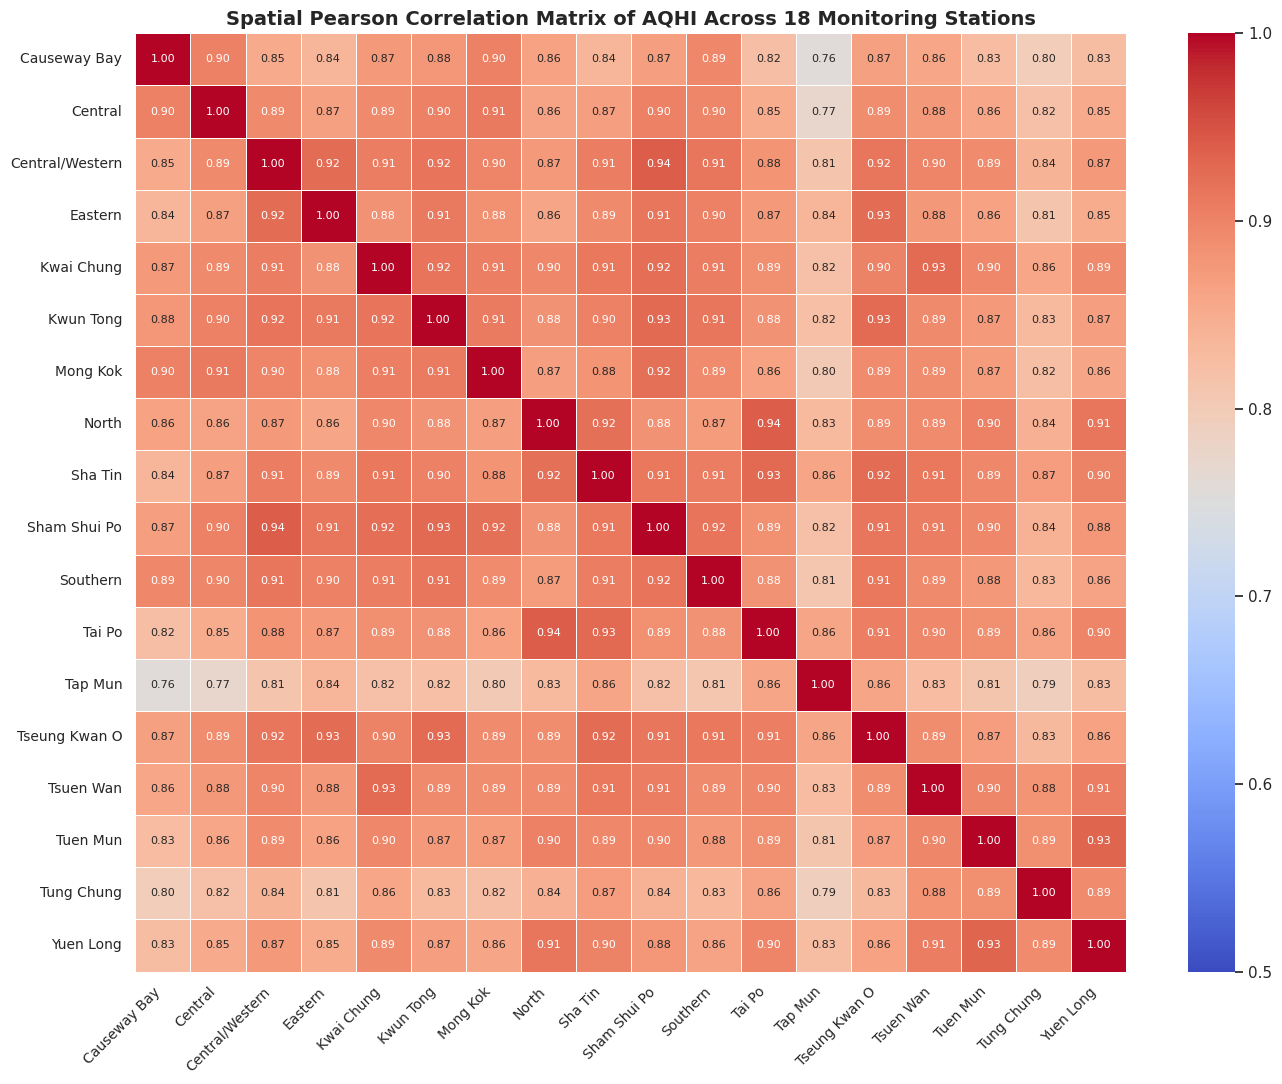

=== 统计检验与效应量计算结果 ===
工作日均值: 3.433, 休息日/节假日均值: 3.445
T-test (Workday vs Restday)      : t = -5.6643, p = 1.4768e-08, Cohen's d = -0.0090
Mann-Whitney U Test             : u = 362088181647.0000, p = 1.6570e-06
ANOVA (Season Differences)      : F = 86213.1277, p = 0.0000e+00, Eta-squared (η²) = 0.1244
執行時間: 5.9916 秒


In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import time

# 記錄開始時間
start_time = time.time()

# 執行的程式碼
#time.sleep(1)  # 範例：暫停 1 秒

# 1. 设置路径与全局绘图风格
output_dir = '/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/Photos/3'
#df = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_features.parquet')

os.makedirs(output_dir, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# 2. 读取数据
df_wide = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_wide.parquet')
df_holidays = pd.read_csv('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/hk_public_holidays_2013_2026.csv')
df_long = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_long.parquet')

# 3. 数据预处理与衍生列构建
df_long['datetime'] = pd.to_datetime(df_long['datetime'])
if 'datetime' in df_wide.columns:
    df_wide['datetime'] = pd.to_datetime(df_wide['datetime'])

# 自动衍生 season 列 (若不存在)
if 'season' not in df_long.columns:
    season_map = {
        12: 'Winter', 1: 'Winter', 2: 'Winter',
        3: 'Spring', 4: 'Spring', 5: 'Spring',
        6: 'Summer', 7: 'Summer', 8: 'Summer',
        9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
    }
    df_long['season'] = df_long['datetime'].dt.month.map(season_map)

# 筛选全港 18 个监测站名称列表 (严格排除非站点元数据列)
known_stations = [
    'Causeway Bay', 'Central', 'Mong Kok', 'Central/Western', 'Eastern',
    'Southern', 'Kwai Chung', 'Kwun Tong', 'Sham Shui Po', 'Tseung Kwan O',
    'Sha Tin', 'Tai Po', 'Tap Mun', 'Tsuen Wan', 'Tuen Mun', 'Yuen Long',
    'Tung Chung', 'North'
]
station_cols = [c for c in df_wide.columns if c in known_stations]

# ==========================================
# 图 6：18 个监测站 AQHI 空间 Pearson 相关系数矩阵热力图 (严格 18×18)
# ==========================================
corr_pearson = df_wide[station_cols].corr(method='pearson')

plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_pearson,
    cmap='coolwarm',
    annot=True,
    fmt=".2f",
    vmin=0.5,
    vmax=1.0,
    linewidths=0.5,
    annot_kws={'size': 8}
)
plt.title('Spatial Pearson Correlation Matrix of AQHI Across 18 Monitoring Stations', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

# 保存图 6
plt.savefig(os.path.join(output_dir, 'chart6_pearson_correlation_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 假设检验与方差分析 (统计推断)
# ==========================================

# 1. 工作日 vs 休息日 (节假日+周末) 判定
df_long['date_str'] = df_long['datetime'].dt.strftime('%Y-%m-%d')
holiday_dates = set(pd.to_datetime(df_holidays['date']).dt.strftime('%Y-%m-%d'))

df_long['is_holiday_gazetted'] = df_long['date_str'].isin(holiday_dates)
df_long['is_weekend'] = df_long['datetime'].dt.dayofweek.isin([5, 6])  # 5: Saturday, 6: Sunday
df_long['is_rest_day'] = df_long['is_holiday_gazetted'] | df_long['is_weekend']

workday_aqhi = df_long[~df_long['is_rest_day']]['aqhi'].dropna().values
restday_aqhi = df_long[df_long['is_rest_day']]['aqhi'].dropna().values

# T 检验与 Mann-Whitney U 检验
t_stat, t_p = stats.ttest_ind(workday_aqhi, restday_aqhi, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(workday_aqhi, restday_aqhi, alternative='two-sided')

# 效应量：Cohen's d
pooled_std = np.sqrt(((len(workday_aqhi)-1)*np.var(workday_aqhi, ddof=1) + (len(restday_aqhi)-1)*np.var(restday_aqhi, ddof=1)) / (len(workday_aqhi) + len(restday_aqhi) - 2))
cohens_d = (np.mean(workday_aqhi) - np.mean(restday_aqhi)) / pooled_std

# 2. 季节单因素方差分析 (ANOVA) 与效应量 Eta-squared (η²)
season_groups = [group['aqhi'].dropna().values for name, group in df_long.groupby('season') if len(group['aqhi'].dropna()) > 0]
f_season_stat, f_season_p = stats.f_oneway(*season_groups)

all_season_data = np.concatenate(season_groups)
grand_mean_season = np.mean(all_season_data)
ss_total_season = np.sum((all_season_data - grand_mean_season)**2)
ss_between_season = sum(len(g) * (np.mean(g) - grand_mean_season)**2 for g in season_groups)
eta_sq_season = ss_between_season / ss_total_season

print("=== 统计检验与效应量计算结果 ===")
print(f"工作日均值: {np.mean(workday_aqhi):.3f}, 休息日/节假日均值: {np.mean(restday_aqhi):.3f}")
print(f"T-test (Workday vs Restday)      : t = {t_stat:.4f}, p = {t_p:.4e}, Cohen's d = {cohens_d:.4f}")
print(f"Mann-Whitney U Test             : u = {u_stat:.4f}, p = {u_p:.4e}")
print(f"ANOVA (Season Differences)      : F = {f_season_stat:.4f}, p = {f_season_p:.4e}, Eta-squared (η²) = {eta_sq_season:.4f}")

# 記錄結束時間
end_time = time.time()

print(f"執行時間: {end_time - start_time:.4f} 秒")

In [17]:
import os
import pandas as pd
import numpy as np
from scipy import stats
import time

# 記錄開始時間
start_time = time.time()

# 執行的程式碼
#time.sleep(1)  # 範例：暫停 1 秒

# 1. 加载数据集
df_wide = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_wide.parquet')
df_long = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_long.parquet')
df_holidays = pd.read_csv('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/hk_public_holidays_2013_2026.csv')

df_long['datetime'] = pd.to_datetime(df_long['datetime'])
if 'datetime' in df_wide.columns:
    df_wide['datetime'] = pd.to_datetime(df_wide['datetime'])

# 明确全港 18 个监测站名称列表
known_stations = [
    'Causeway Bay', 'Central', 'Mong Kok', 'Central/Western', 'Eastern',
    'Southern', 'Kwai Chung', 'Kwun Tong', 'Sham Shui Po', 'Tseung Kwan O',
    'Sha Tin', 'Tai Po', 'Tap Mun', 'Tsuen Wan', 'Tuen Mun', 'Yuen Long',
    'Tung Chung', 'North'
]
station_cols = [c for c in df_wide.columns if c in known_stations]

# ==========================================
# 维度 1：监测站间 Pearson 空间相关性精确提取
# ==========================================
corr_matrix = df_wide[station_cols].corr(method='pearson')

st_tw_corr = corr_matrix.loc['Sha Tin', 'Tsuen Wan'] if 'Sha Tin' in corr_matrix.index and 'Tsuen Wan' in corr_matrix.columns else np.nan
cb_tm_corr = corr_matrix.loc['Causeway Bay', 'Tap Mun'] if 'Causeway Bay' in corr_matrix.index and 'Tap Mun' in corr_matrix.columns else np.nan

# 计算排除自相关 (r=1.0) 后的全港最强与最弱相关站点对
mask = np.ones_like(corr_matrix, dtype=bool)
np.fill_diagonal(mask, False)
unstacked_corr = corr_matrix.where(mask).unstack().dropna()
max_corr_pair = unstacked_corr.idxmax()
max_corr_val = unstacked_corr.max()
min_corr_pair = unstacked_corr.idxmin()
min_corr_val = unstacked_corr.min()

print("==========================================")
print("1. 监测站间空间 Pearson 相关系数精确核验")
print("==========================================")
print(f"Sha Tin 与 Tsuen Wan 相关系数: r = {st_tw_corr:.4f}")
print(f"Causeway Bay 与 Tap Mun 相关系数: r = {cb_tm_corr:.4f}")
print(f"全港最高相关性站点对: {max_corr_pair[0]} - {max_corr_pair[1]} (r = {max_corr_val:.4f})")
print(f"全港最低相关性站点对: {min_corr_pair[0]} - {min_corr_pair[1]} (r = {min_corr_val:.4f})")

# ==========================================
# 维度 2：工作日 vs 假期 假设检验 (提供两种统计划分类别)
# ==========================================
df_long['date_str'] = df_long['datetime'].dt.strftime('%Y-%m-%d')
holiday_dates = set(pd.to_datetime(df_holidays['date']).dt.strftime('%Y-%m-%d'))

df_long['is_holiday_gazetted'] = df_long['date_str'].isin(holiday_dates)
df_long['is_weekend'] = df_long['datetime'].dt.dayofweek.isin([5, 6])
df_long['is_rest_day'] = df_long['is_holiday_gazetted'] | df_long['is_weekend']

# 补全站点类型与季节映射
roadside_stations = ['Causeway Bay', 'Central', 'Mong Kok']
df_long['station_type'] = np.where(df_long['station'].isin(roadside_stations), 'Roadside', 'General')
season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring', 6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
df_long['season'] = df_long['datetime'].dt.month.map(season_map)

def run_two_sample_test(group1_data, group2_data, g1_name, g2_name):
    g1 = group1_data.dropna().values
    g2 = group2_data.dropna().values

    n1, n2 = len(g1), len(g2)
    mean1, mean2 = np.mean(g1), np.mean(g2)
    std1, std2 = np.std(g1, ddof=1), np.std(g2, ddof=1)

    t_stat, t_p = stats.ttest_ind(g1, g2, equal_var=False)
    u_stat, u_p = stats.mannwhitneyu(g1, g2, alternative='two-sided')

    pooled_std = np.sqrt(((n1 - 1) * std1**2 + (n2 - 1) * std2**2) / (n1 + n2 - 2))
    cohens_d = (mean1 - mean2) / pooled_std

    return pd.DataFrame([
        {'组别': g1_name, '样本量 (n)': f"{n1:,}", 'AQHI 均值': f"{mean1:.3f}", '标准差 (Std)': f"{std1:.3f}", 'Welch t 统计量': f"{t_stat:.4f}", 't p-value': f"{t_p:.4e}", 'Mann-Whitney U': f"{u_stat:.2e}", 'U p-value': f"{u_p:.4e}", "Cohen's d": f"{cohens_d:.4f}"},
        {'组别': g2_name, '样本量 (n)': f"{n2:,}", 'AQHI 均值': f"{mean2:.3f}", '标准差 (Std)': f"{std2:.3f}", 'Welch t 统计量': '-', 't p-value': '-', 'Mann-Whitney U': '-', 'U p-value': '-', "Cohen's d": '-'}
    ])

# 划分 A: 周一至周五非假 vs 休息日(周末+法定假)
workday_aqhi = df_long[~df_long['is_rest_day']]['aqhi']
restday_aqhi = df_long[df_long['is_rest_day']]['aqhi']
test_res_restday = run_two_sample_test(workday_aqhi, restday_aqhi, '工作日 (Mon-Fri Non-Holiday)', '休息日 (Weekend + Public Holiday)')

# 划分 B: 非法定假日 vs 仅法定公众假期
workday_strict_aqhi = df_long[~df_long['is_holiday_gazetted']]['aqhi']
pubholiday_aqhi = df_long[df_long['is_holiday_gazetted']]['aqhi']
test_res_pubholiday = run_two_sample_test(workday_strict_aqhi, pubholiday_aqhi, '非法定假日 (Non-Holiday)', '仅法定公众假期 (Public Holiday Only)')

print("\n==========================================")
print("2. 假设检验：工作日 vs 假期 真实精确数据")
print("==========================================")
print("[划分方式 A: 工作日 vs 休息日(含周末+法定假)]")
print(test_res_restday.to_markdown(index=False))
print("\n[划分方式 B: 非法定假日 vs 仅法定公众假期(不含普通周末)]")
print(test_res_pubholiday.to_markdown(index=False))

# ==========================================
# 维度 3：单因素方差分析 (ANOVA) 与效应量 Eta-squared (η²) 提取
# ==========================================
def run_anova_test(df, group_col, target_col='aqhi'):
    df_clean = df.dropna(subset=[group_col, target_col])
    groups = [group[target_col].values for name, group in df_clean.groupby(group_col)]

    f_stat, p_val = stats.f_oneway(*groups)

    k = len(groups)
    N = len(df_clean)
    df_between = k - 1
    df_within = N - k

    all_data = df_clean[target_col].values
    grand_mean = np.mean(all_data)
    ss_total = np.sum((all_data - grand_mean)**2)
    ss_between = sum(len(g) * (np.mean(g) - grand_mean)**2 for g in groups)
    eta_sq = ss_between / ss_total

    return {
        '检验维度': group_col,
        '组别数量': k,
        '自由度 df (Between, Within)': f"({df_between}, {df_within:,})",
        'F 统计量': f"{f_stat:.4f}",
        'p-value': f"{p_val:.4e}",
        '效应量 Eta-squared (η²)': f"{eta_sq:.4f}"
    }

anova_season = run_anova_test(df_long, 'season')
anova_type = run_anova_test(df_long, 'station_type')
anova_df = pd.DataFrame([anova_season, anova_type])

print("\n==========================================")
print("3. 单因素方差分析 (ANOVA) 真实精确数据")
print("==========================================")
print(anova_df.to_markdown(index=False))

# 記錄結束時間
end_time = time.time()

print(f"執行時間: {end_time - start_time:.4f} 秒")

1. 监测站间空间 Pearson 相关系数精确核验
Sha Tin 与 Tsuen Wan 相关系数: r = 0.9139
Causeway Bay 与 Tap Mun 相关系数: r = 0.7570
全港最高相关性站点对: Central/Western - Sham Shui Po (r = 0.9401)
全港最低相关性站点对: Causeway Bay - Tap Mun (r = 0.7570)

2. 假设检验：工作日 vs 假期 真实精确数据
[划分方式 A: 工作日 vs 休息日(含周末+法定假)]
| 组别                              | 样本量 (n)   |   AQHI 均值 |   标准差 (Std) | Welch t 统计量   | t p-value   | Mann-Whitney U   | U p-value   | Cohen's d   |
|:----------------------------------|:-------------|------------:|---------------:|:-----------------|:------------|:-----------------|:------------|:------------|
| 工作日 (Mon-Fri Non-Holiday)      | 1,229,219    |       3.433 |          1.337 | -5.6643          | 1.4768e-08  | 3.62e+11         | 1.6570e-06  | -0.0090     |
| 休息日 (Weekend + Public Holiday) | 591,647      |       3.445 |          1.344 | -                | -           | -                | -           | -           |

[划分方式 B: 非法定假日 vs 仅法定公众假期(不含普通周末)]
| 组别                                 | 样本量 (n)   |   AQHI 均值 | 

In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import time

# 記錄開始時間
start_time = time.time()

# 執行的程式碼
#time.sleep(1)  # 範例：暫停 1 秒

# 1. 路径设置与绘图风格
save_dir = '/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/Photos'
os.makedirs(save_dir, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# 2. 读取数据
df_daily = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_daily.parquet')
df_long = pd.read_parquet('/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part2_zdx/replicate/aqhi_clean_long.parquet')

df_daily['date'] = pd.to_datetime(df_daily['date'])
df_long['datetime'] = pd.to_datetime(df_long['datetime'])
df_long['month'] = df_long['datetime'].dt.month
df_long['hour'] = df_long['datetime'].dt.hour

roadside_stations = ['Causeway Bay', 'Central', 'Mong Kok']
df_long['station_type'] = np.where(df_long['station'].isin(roadside_stations), 'Roadside', 'General')
df_daily['station_type'] = np.where(df_daily['station'].isin(roadside_stations), 'Roadside', 'General')

# ==========================================
# 图 1：全港 AQHI 长期时间序列演变趋势图
# ==========================================
df_daily_overall = df_daily.groupby('date')['aqhi_daily_mean'].mean().reset_index()

plt.figure(figsize=(14, 6))
plt.plot(df_daily_overall['date'], df_daily_overall['aqhi_daily_mean'], color='#1f77b4', linewidth=0.8, alpha=0.4, label='Territory-wide Daily Mean')

df_daily_overall['ma_30'] = df_daily_overall['aqhi_daily_mean'].rolling(window=30).mean()
plt.plot(df_daily_overall['date'], df_daily_overall['ma_30'], color='crimson', linewidth=2, label='30-Day Moving Average')

plt.axhline(y=7, color='orange', linestyle='--', linewidth=1.5, label='High Risk Threshold (AQHI = 7)')
plt.axhline(y=10, color='red', linestyle='--', linewidth=1.5, label='Serious Risk Threshold (AQHI = 10)')

plt.title('Territory-wide AQHI Long-term Trend & 30-Day Moving Average (2014-2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Daily Mean AQHI', fontsize=12)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(f'{save_dir}/chart1_trend_moving_avg.png', dpi=300, bbox_inches='tight')
plt.close()

# ==========================================
# 图 2：监测站点及类型 AQHI 分布对比箱线图
# ==========================================
order = df_daily.groupby('station')['aqhi_daily_mean'].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df_daily,
    x='station',
    y='aqhi_daily_mean',
    order=order,
    hue='station_type',
    palette={'Roadside': '#e74c3c', 'General': '#3498db'},
    dodge=False
)

plt.axhline(y=7, color='orange', linestyle='--', linewidth=1.2, label='High Risk Threshold (AQHI = 7)')
plt.axhline(y=10, color='red', linestyle='--', linewidth=1.2, label='Serious Risk Threshold (AQHI = 10)')

plt.title('Distribution of Daily Mean AQHI Across 18 Stations (Roadside vs. General)', fontsize=14, fontweight='bold')
plt.xlabel('Monitoring Station', fontsize=12)
plt.ylabel('Daily Mean AQHI', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Station Type', loc='upper right')
plt.tight_layout()
plt.savefig(f'{save_dir}/chart2_boxplot_station_type.png', dpi=300, bbox_inches='tight')
plt.close()

# ==========================================
# 图 3：24小时昼夜 vs 12个月份交叉平均 AQHI 热力图
# ==========================================
heatmap_data = df_long.pivot_table(index='hour', columns='month', values='aqhi', aggfunc='mean')

plt.figure(figsize=(11, 8))
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt=".2f", cbar_kws={'label': 'Mean AQHI'}, linewidths=0.5)
plt.title('Average AQHI Heatmap: Hour of Day vs. Month (Territory-wide)', fontsize=14, fontweight='bold')
plt.xlabel('Month (1-12)', fontsize=12)
plt.ylabel('Hour of Day (0-23)', fontsize=12)
plt.tight_layout()
plt.savefig(f'{save_dir}/chart3_heatmap_hour_month.png', dpi=300, bbox_inches='tight')
plt.close()

# ==========================================
# 图 4：各监测站 AQHI≥10 严重风险累计小时数分布图 (基于 df_long 精确计算)
# ==========================================
df_long['is_10plus'] = (df_long['aqhi'] >= 10).astype(int)
hours_10plus_series = df_long.groupby('station')['is_10plus'].sum().sort_values(ascending=False)

plt.figure(figsize=(13, 6))
sns.barplot(x=hours_10plus_series.index, y=hours_10plus_series.values, palette='Reds_r')

# 添加柱状图数值标签
for i, v in enumerate(hours_10plus_series.values):
    plt.text(i, v + 5, str(v), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Cumulative Hourly Risk Exposure (AQHI ≥ 10) by Station (2014-2026)', fontsize=14, fontweight='bold')
plt.xlabel('Monitoring Station', fontsize=12)
plt.ylabel('Cumulative Hours (AQHI ≥ 10)', fontsize=12)
plt.xticks(rotation=45)
plt.ylim(0, max(hours_10plus_series.values) * 1.1)
plt.tight_layout()
plt.savefig(f'{save_dir}/chart4_10plus_hours.png', dpi=300, bbox_inches='tight')
plt.close()

# 输出核验数据
print("✅ 图 1 ~ 图 4 重新绘制并完成保存。")
print("\n--- 关键指标精确数据核验结果 ---")
print(f"屯门 (Tuen Mun) 累计 AQHI>=10 小时数: {hours_10plus_series['Tuen Mun']}")
print(f"东涌 (Tung Chung) 累计 AQHI>=10 小时数: {hours_10plus_series['Tung Chung']}")
print(f"铜锣湾 (Causeway Bay) 累计 AQHI>=10 小时数: {hours_10plus_series['Causeway Bay']}")
print(f"元朗 (Yuen Long) 累计 AQHI>=10 小时数: {hours_10plus_series['Yuen Long']}")
roadside_sum = hours_10plus_series[['Causeway Bay', 'Central', 'Mong Kok']].sum()
total_sum = hours_10plus_series.sum()
print(f"3个路边站累计: {roadside_sum} 小时 (占比: {roadside_sum/total_sum*100:.2f}%)")

# 記錄結束時間
end_time = time.time()

print(f"執行時間: {end_time - start_time:.4f} 秒")

/var/folders/dn/8xt3xqsn3ysf586z6l0zvfym0000gn/T/ipykernel_3048/4078303756.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=hours_10plus_series.index, y=hours_10plus_series.values, palette='Reds_r')


✅ 图 1 ~ 图 4 重新绘制并完成保存。

--- 关键指标精确数据核验结果 ---
屯门 (Tuen Mun) 累计 AQHI>=10 小时数: 465
东涌 (Tung Chung) 累计 AQHI>=10 小时数: 388
铜锣湾 (Causeway Bay) 累计 AQHI>=10 小时数: 337
元朗 (Yuen Long) 累计 AQHI>=10 小时数: 333
3个路边站累计: 833 小时 (占比: 22.05%)
執行時間: 5.7846 秒
